# 01 · EDA — UCI incident event log (Sprint 1)

Supports **FR-16** (open-time features + written leakage check) and **NFR-12** (seed 42, time-based split).

Data: `data/raw/incident_event_log.csv` — UCI "Incident management process enriched event log" (CC BY 4.0). Public, anonymised data only.

Questions answered here:
1. Shape, types, missing values, unique incidents
2. One row per incident (open-time values from first event, outcomes from last event)
3. `made_sla`: which value means "breached" (proved with data)
4. Breach rate overall and by segment
5. Hypothesis: more reassignments → more breaches?
6. Leakage check for the candidate features
7. Date range of `opened_at` for the time-based split

No model is trained in this notebook.

In [1]:
import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

SEED = 42  # NFR-12
random.seed(SEED)
np.random.seed(SEED)

pd.set_option("display.max_columns", 60)
pd.set_option("display.width", 200)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.alpha": 0.25, "axes.axisbelow": True})

BAR = "#3b6ea5"
REF = "#c0392b"
DATA_PATH = "../data/raw/incident_event_log.csv"

## 1. Shape, column types, missing values, unique incidents

The file uses `?` for unknown values, so it is read as missing (`NaN`). Everything is loaded as text first and then converted explicitly, so nothing is guessed silently.

In [2]:
raw = pd.read_csv(DATA_PATH, dtype=str, keep_default_na=False, na_values=["?"])
print("Event rows x columns:", raw.shape)
print("Unique incidents (number):", raw["number"].nunique())
print("Empty strings in file:", int((raw == "").sum().sum()))

df = raw.copy()
DATE_COLS = ["opened_at", "sys_created_at", "sys_updated_at", "resolved_at", "closed_at"]
for c in DATE_COLS:  # day/month/year in the file, e.g. 29/2/2016 01:16
    df[c] = pd.to_datetime(df[c], format="%d/%m/%Y %H:%M")
for c in ["reassignment_count", "reopen_count", "sys_mod_count"]:
    df[c] = df[c].astype(int)
for c in ["active", "made_sla", "knowledge", "u_priority_confirmation"]:
    assert set(df[c].unique()) <= {"true", "false"}, c
    df[c] = df[c].eq("true")

events_per_incident = df.groupby("number").size()
print("Events per incident: min %d, median %d, mean %.1f, max %d" % (
    events_per_incident.min(), events_per_incident.median(), events_per_incident.mean(), events_per_incident.max()))

Event rows x columns: (141712, 36)
Unique incidents (number): 24918
Empty strings in file: 0


Events per incident: min 2, median 5, mean 5.7, max 58


In [3]:
overview = pd.DataFrame({
    "dtype": df.dtypes.astype(str),
    "unique_values": raw.nunique(),
    "missing_rows ('?')": raw.isna().sum(),
    "missing_%": (raw.isna().mean() * 100).round(1),
    "example": raw.apply(lambda s: s.dropna().iloc[0]),
})
overview

,dtype,unique_values,missing_rows ('?'),missing_%,example
number,object,24918,0,0.0,INC0000045
incident_state,object,9,0,0.0,New
active,bool,2,0,0.0,true
reassignment_count,int64,28,0,0.0,0
reopen_count,int64,9,0,0.0,0
sys_mod_count,int64,115,0,0.0,0
made_sla,bool,2,0,0.0,true
caller_id,object,5244,29,0.0,Caller 2403
opened_by,object,207,4835,3.4,Opened by 8
opened_at,datetime64[ns],19849,0,0.0,29/2/2016 01:16


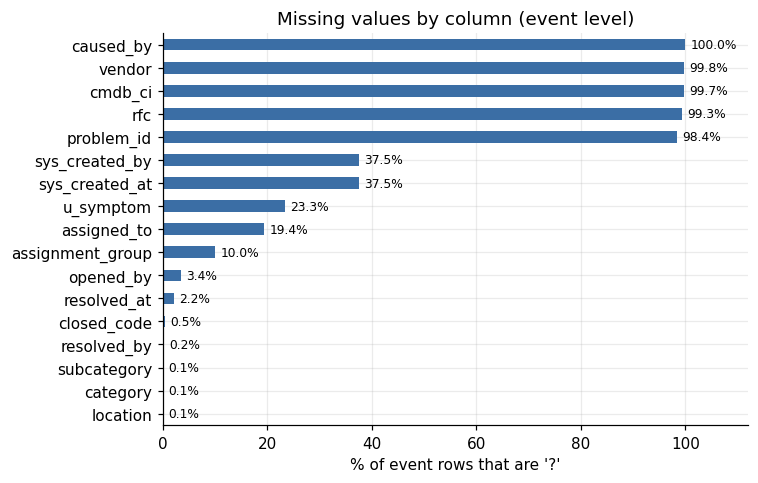

In [4]:
miss = overview["missing_%"][overview["missing_%"] > 0].sort_values()
ax = miss.plot.barh(figsize=(7, 4.5), color=BAR)
ax.set_xlabel("% of event rows that are '?'")
ax.set_title("Missing values by column (event level)")
for i, v in enumerate(miss):
    ax.text(v + 1, i, f"{v:.1f}%", va="center", fontsize=8)
ax.set_xlim(0, 112)
plt.tight_layout(); plt.show()

**Reading this:** 141,712 event rows, 36 columns, 24,918 incidents (about 5.7 events each). The candidate model features are almost complete at event level except `u_symptom` (23% missing) and `assignment_group` (10%). The columns that are nearly all `?` (`cmdb_ci`, `problem_id`, `rfc`, `vendor`, `caused_by`) carry no usable signal.

## 2. One row per incident

Events are sorted inside each incident by `sys_mod_count` (ServiceNow's update counter), then `sys_updated_at`.
- **Open-time values** = the first event (suffix `_open`).
- **Outcome values** = the last event (suffix `_final`).

In [5]:
df["_row"] = np.arange(len(df))  # original file order, used only as a tie-breaker
df = df.sort_values(["number", "sys_mod_count", "sys_updated_at", "_row"], kind="mergesort").reset_index(drop=True)

g = df.groupby("number", sort=False)
first, last = g.first(skipna=False), g.last(skipna=False)   # skipna=False: keep '?' as missing, do not borrow later values

print("State of the first event :", first["incident_state"].value_counts().to_dict())
print("sys_mod_count of first event:", first["sys_mod_count"].value_counts().to_dict())
print("State of the last event  :", last["incident_state"].value_counts().to_dict())
print("opened_at / resolved_at / closed_at vary inside an incident:",
      {c: int((g[c].nunique(dropna=False) > 1).sum()) for c in ["opened_at", "resolved_at", "closed_at"]})

State of the first event : {'New': 16396, 'Active': 6504, 'Resolved': 1819, 'Awaiting User Info': 193, 'Awaiting Problem': 6}
sys_mod_count of first event: {0: 24913, 1: 5}
State of the last event  : {'Closed': 24918}
opened_at / resolved_at / closed_at vary inside an incident: {'opened_at': 0, 'resolved_at': 0, 'closed_at': 0}


In [6]:
CANDIDATES = ["contact_type", "category", "subcategory", "u_symptom", "impact", "urgency",
              "priority", "assignment_group", "knowledge"]

inc = pd.DataFrame(index=first.index)
inc["opened_at"] = first["opened_at"]
for c in CANDIDATES + ["location", "u_priority_confirmation", "made_sla", "incident_state"]:
    inc[c + "_open"] = first[c]
inc["open_hour"] = inc["opened_at"].dt.hour
inc["open_weekday"] = inc["opened_at"].dt.day_name()

# outcome values (last event) -- never to be used as model features
for c in CANDIDATES:
    inc[c + "_final"] = last[c]
inc["made_sla_final"] = last["made_sla"]
inc["reassignment_count_final"] = last["reassignment_count"]
inc["reopen_count_final"] = last["reopen_count"]
inc["sys_mod_count_final"] = last["sys_mod_count"]
inc["n_events"] = g.size()
inc["resolved_at"] = last["resolved_at"]
inc["closed_at"] = last["closed_at"]
inc["hours_to_resolve"] = (inc["resolved_at"] - inc["opened_at"]).dt.total_seconds() / 3600
inc["hours_to_close"] = (inc["closed_at"] - inc["opened_at"]).dt.total_seconds() / 3600

print("Incident table:", inc.shape)
inc.head()

Incident table: (24918, 34)


,opened_at,contact_type_open,category_open,subcategory_open,u_symptom_open,impact_open,urgency_open,priority_open,assignment_group_open,knowledge_open,location_open,u_priority_confirmation_open,made_sla_open,incident_state_open,open_hour,open_weekday,contact_type_final,category_final,subcategory_final,u_symptom_final,impact_final,urgency_final,priority_final,assignment_group_final,knowledge_final,made_sla_final,reassignment_count_final,reopen_count_final,sys_mod_count_final,n_events,resolved_at,closed_at,hours_to_resolve,hours_to_close
number,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,
INC0000045,2016-02-29 01:16:00,Phone,Category 55,Subcategory 170,Symptom 72,2 - Medium,2 - Medium,3 - Moderate,Group 56,True,Location 143,False,True,New,1,Monday,Phone,Category 55,Subcategory 170,Symptom 72,2 - Medium,2 - Medium,3 - Moderate,Group 56,True,True,0,0,4,4,2016-02-29 11:29:00,2016-03-05 12:00:00,10.216667,130.733333
INC0000047,2016-02-29 04:40:00,Phone,Category 40,Subcategory 215,Symptom 471,2 - Medium,2 - Medium,3 - Moderate,Group 70,True,Location 165,False,True,New,4,Monday,Phone,Category 40,Subcategory 215,Symptom 471,2 - Medium,2 - Medium,3 - Moderate,Group 24,True,True,1,0,8,9,2016-03-01 09:52:00,2016-03-06 10:00:00,29.200000,149.333333
INC0000057,2016-02-29 06:10:00,Phone,Category 20,Subcategory 125,Symptom 471,2 - Medium,2 - Medium,3 - Moderate,Group 70,True,Location 204,False,True,New,6,Monday,Phone,Category 20,Subcategory 125,Symptom 471,2 - Medium,2 - Medium,3 - Moderate,Group 70,True,True,0,0,6,7,2016-03-01 02:55:00,2016-03-06 03:00:00,20.750000,140.833333
INC0000060,2016-02-29 06:38:00,Phone,Category 9,Subcategory 97,Symptom 450,2 - Medium,2 - Medium,3 - Moderate,Group 25,True,Location 204,False,True,New,6,Monday,Phone,Category 9,Subcategory 97,Symptom 450,2 - Medium,2 - Medium,3 - Moderate,Group 25,True,True,0,0,3,4,2016-03-02 12:06:00,2016-03-07 13:00:00,53.466667,174.366667
INC0000062,2016-02-29 06:58:00,Phone,Category 53,Subcategory 168,Symptom 232,2 - Medium,2 - Medium,3 - Moderate,Group 70,True,Location 93,False,True,New,6,Monday,Phone,Category 53,Subcategory 168,Symptom 232,1 - High,2 - Medium,2 - High,Group 23,True,False,1,0,7,8,2016-02-29 15:51:00,2016-03-05 16:00:00,8.883333,129.033333


**Notes on the build**
- Every incident ends in `Closed`, so every incident has a final outcome (no open tickets in the data).
- `opened_at`, `resolved_at` and `closed_at` are the same on every event of an incident. The resolved/closed timestamps are therefore *back-filled* onto the first event by whoever built the log. This matters for leakage (section 6): "the value is on the first row" does not always mean "it was known at open".
- Not every first event is `New`: some incidents are first logged as `Active` or already `Resolved`.

## 3. `made_sla`: which value means "breached"?

Not assumed. Three independent checks:
- **A.** Time to resolve/close, split by the final `made_sla`.
- **B.** How `made_sla` moves inside an incident over time (a ticket starts inside its SLA and can only fall out of it).
- **C.** The same split inside each priority (SLA targets differ by priority, so check the direction holds in each).

In [7]:
vc = pd.DataFrame({
    "event rows": df["made_sla"].value_counts(),
    "incidents (first event)": inc["made_sla_open"].value_counts(),
    "incidents (last event)": inc["made_sla_final"].value_counts(),
}).fillna(0).astype(int)
vc.loc["share true %"] = (vc.loc[True] / vc.sum() * 100).round(1)
vc

,event rows,incidents (first event),incidents (last event)
True,132497.0,24917.0,15803.0
False,9215.0,1.0,9115.0
share true %,93.5,100.0,63.4


In [8]:
# Check A: resolution time by final made_sla
def q(p):
    f = lambda s: s.quantile(p)
    f.__name__ = f"p{int(p*100)}"
    return f

check_a = inc.groupby("made_sla_final")[["hours_to_resolve", "hours_to_close"]].agg(["count", q(.25), "median", q(.75), q(.90)]).round(1)
print("Negative hours_to_resolve (resolved_at before opened_at):", int((inc["hours_to_resolve"] < 0).sum()),
      "| missing resolved_at:", int(inc["resolved_at"].isna().sum()))
check_a

Negative hours_to_resolve (resolved_at before opened_at): 0 | missing resolved_at: 1556


hours_to_resolve                             hours_to_close                             
                          count    p25 median    p75    p90          count    p25 median    p75     p90
made_sla_final                                                                                         
False                      8930  113.1  201.4  395.0  893.2           9115  290.0  401.8  555.5  1128.8
True                      14432    0.2    1.1   23.1   61.7          15803  120.7  121.4  143.8   187.2

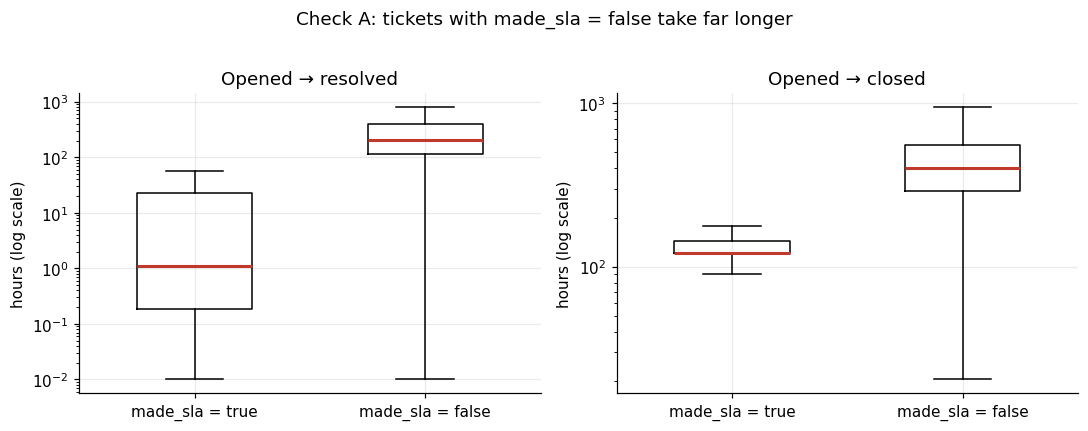

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(10, 3.8))
for ax, col, title in zip(axes, ["hours_to_resolve", "hours_to_close"], ["Opened → resolved", "Opened → closed"]):
    data = [inc.loc[inc["made_sla_final"] == v, col].dropna().clip(lower=0.01) for v in [True, False]]
    ax.boxplot(data, tick_labels=["made_sla = true", "made_sla = false"], showfliers=False, widths=0.5,
               medianprops=dict(color=REF, linewidth=2))
    ax.set_yscale("log"); ax.set_ylabel("hours (log scale)"); ax.set_title(title)
fig.suptitle("Check A: tickets with made_sla = false take far longer", y=1.02)
plt.tight_layout(); plt.show()

In [10]:
# Check B: direction of change of made_sla inside an incident
prev = g["made_sla"].shift()
flips = pd.Series(np.where(prev.isna() | (prev == df["made_sla"]), "no change",
                  np.where(prev & ~df["made_sla"], "true -> false", "false -> true")), index=df.index)
check_b = pd.DataFrame({
    "event rows": flips.value_counts(),
    "incidents with at least one": flips[flips != "no change"].groupby(df["number"]).unique().explode().value_counts(),
}).fillna(0).astype(int)
display(check_b)

path = pd.crosstab(inc["made_sla_open"], inc["made_sla_final"], margins=True)
path.index.name, path.columns.name = "made_sla at first event", "made_sla at last event"
path

,event rows,incidents with at least one
no change,132598,0
true -> false,9114,9114


made_sla at last event,False,True,All
made_sla at first event,,,
False,1,0,1
True,9114,15803,24917
All,9115,15803,24918


In [11]:
# Check C: same comparison inside each priority (priority at open)
check_c = (inc.groupby(["priority_open", "made_sla_final"])["hours_to_resolve"]
             .agg(["count", "median"]).round(1).unstack("made_sla_final"))
check_c.columns = [f"{a} | made_sla={b}" for a, b in check_c.columns]
check_c

,count | made_sla=False,count | made_sla=True,median | made_sla=False,median | made_sla=True
priority_open,,,,
1 - Critical,149,36,91.0,20.6
2 - High,302,9,52.7,17.5
3 - Moderate,8370,13855,210.0,1.1
4 - Low,109,532,669.4,0.8


In [12]:
# Check D (extra): which clock does made_sla follow? Best single cut-off in hours for '3 - Moderate' (95% of tickets),
# using time-to-resolve vs time-to-close. Final priority is used because the SLA target follows the current priority.
p3 = inc[inc["priority_final"] == "3 - Moderate"]
rows = []
for col in ["hours_to_resolve", "hours_to_close"]:
    x = p3[[col, "made_sla_final"]].dropna()
    acc, cut = max((((x[col] > t) == ~x["made_sla_final"]).mean(), t) for t in np.arange(24, 400, 2))
    rows.append({"clock": col, "best_cut_hours": int(cut), "best_cut_days": round(cut / 24, 1),
                 "share_of_tickets_explained_%": round(acc * 100, 1), "tickets": len(x)})
pd.DataFrame(rows).set_index("clock")

,best_cut_hours,best_cut_days,share_of_tickets_explained_%,tickets
clock,,,,
hours_to_resolve,92,3.8,90.9,22010
hours_to_close,218,9.1,97.9,23466


**Answer: `made_sla = false` means the SLA was breached.** The target is `breached = not made_sla`, read from the **last** event.

- **A.** Tickets that end with `made_sla = false` took a median of **201 hours** to resolve; tickets ending `true` took **1.1 hours**. Slow tickets are the `false` ones.
- **B.** `made_sla` is `true` on the first event of 24,917 of 24,918 incidents. Inside an incident it only ever moves `true → false` (9,114 times) and never back. A ticket starts inside its SLA and can only fall out of it — that is how a "still within SLA" flag behaves.
- **C.** The direction holds inside every priority (for example Moderate: 210 h vs 1.1 h).
- **D.** For Moderate tickets, a single cut-off on **time to close** (about 218 h ≈ 9 days) reproduces `made_sla` for 97.9% of tickets; the best cut-off on time to resolve only reaches 90.9%. So the flag looks like it follows the clock to *closure*, not to resolution. This is an inference from the data, not documented by UCI.

Two consequences:
- `made_sla` changes during the life of a ticket, so only its **final** value is the label. The event-level share (93.5% true) is not the compliance rate.
- `made_sla` at open is always `true`, so it carries no information and is not a feature.

In [13]:
inc["breached"] = ~inc["made_sla_final"]   # FR-16 target: breach = not made_sla (final value)
overall = inc["breached"].mean()
print(f"Overall breach rate: {overall:.1%}  ({inc['breached'].sum():,} of {len(inc):,} incidents)")

Overall breach rate: 36.6%  (9,115 of 24,918 incidents)


## 4. Breach rate overall and by segment

Segments use the **open-time** value (first event), because that is what the model will see. Small groups are noisy, so high-cardinality columns show the 15 largest groups, and every table carries the incident count.

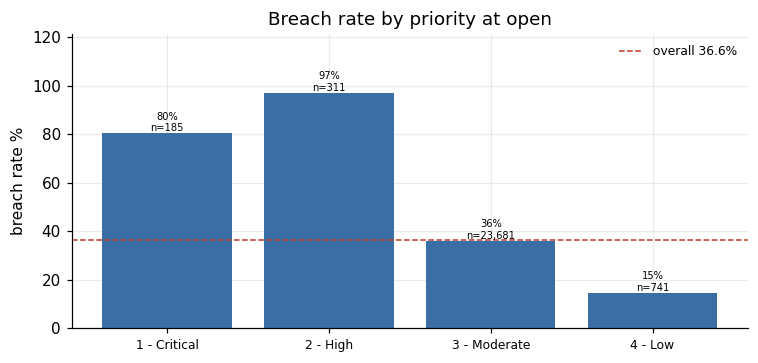

,incidents,breaches,share_of_incidents_%,breach_rate_%
priority_open,,,,
1 - Critical,185,149,0.7,80.5
2 - High,311,302,1.2,97.1
3 - Moderate,23681,8555,95.0,36.1
4 - Low,741,109,3.0,14.7


In [14]:
def breach_table(col, order=None, top=None):
    t = (inc.assign(_k=inc[col].astype(object).where(inc[col].notna(), "(missing)"))
            .groupby("_k")["breached"].agg(incidents="size", breaches="sum", breach_rate="mean"))
    t.index.name = col
    t["share_of_incidents_%"] = (t["incidents"] / len(inc) * 100).round(1)
    t = t.loc[[o for o in order if o in t.index]] if order is not None else t.sort_values("incidents", ascending=False)
    n_groups = len(t)
    if top:
        t = t.head(top)
    t["breach_rate_%"] = (t.pop("breach_rate") * 100).round(1)
    t.attrs["n_groups"] = n_groups
    return t

def breach_plot(t, title, rotate=0, figsize=(7, 3.4)):
    fig, ax = plt.subplots(figsize=figsize)
    x = [str(i) for i in t.index]
    ax.bar(x, t["breach_rate_%"], color=BAR)
    ax.axhline(overall * 100, color=REF, ls="--", lw=1, label=f"overall {overall:.1%}")
    ax.set_ylabel("breach rate %"); ax.set_title(title); ax.legend(frameon=False, fontsize=8)
    if len(t) <= 16:
        for i, (v, n) in enumerate(zip(t["breach_rate_%"], t["incidents"])):
            ax.text(i, v + 0.8, f"{v:.0f}%\nn={n:,}", ha="center", fontsize=6.5)
        ax.set_ylim(0, max(t["breach_rate_%"].max() * 1.25, 10))
    plt.setp(ax.get_xticklabels(), rotation=rotate, ha="right" if rotate else "center", fontsize=8)
    plt.tight_layout(); plt.show()

def segment(col, title, order=None, top=None, rotate=0, figsize=(7, 3.4)):
    t = breach_table(col, order, top)
    if top and t.attrs["n_groups"] > top:
        title += f" (top {top} of {t.attrs['n_groups']} by volume)"
    breach_plot(t, title, rotate, figsize)
    return t

segment("priority_open", "Breach rate by priority at open", order=sorted(inc["priority_open"].unique()))

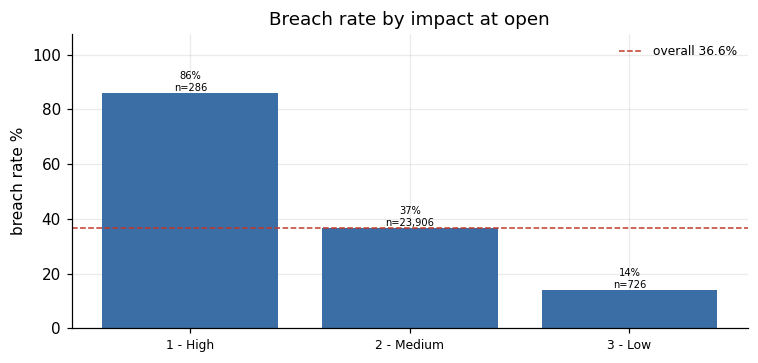

,incidents,breaches,share_of_incidents_%,breach_rate_%
impact_open,,,,
1 - High,286,246,1.1,86.0
2 - Medium,23906,8767,95.9,36.7
3 - Low,726,102,2.9,14.0


In [15]:
segment("impact_open", "Breach rate by impact at open", order=sorted(inc["impact_open"].unique()))

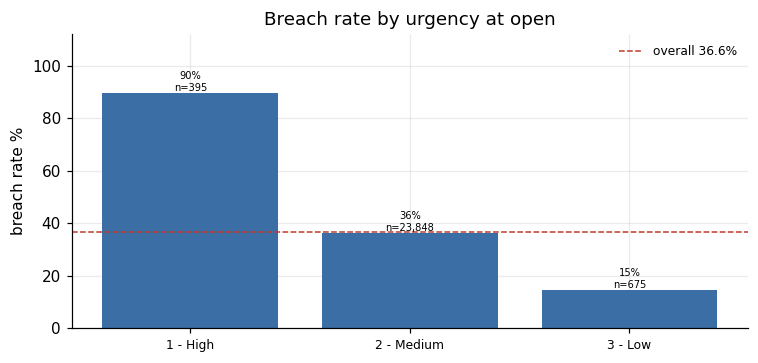

,incidents,breaches,share_of_incidents_%,breach_rate_%
urgency_open,,,,
1 - High,395,354,1.6,89.6
2 - Medium,23848,8662,95.7,36.3
3 - Low,675,99,2.7,14.7


In [16]:
segment("urgency_open", "Breach rate by urgency at open", order=sorted(inc["urgency_open"].unique()))

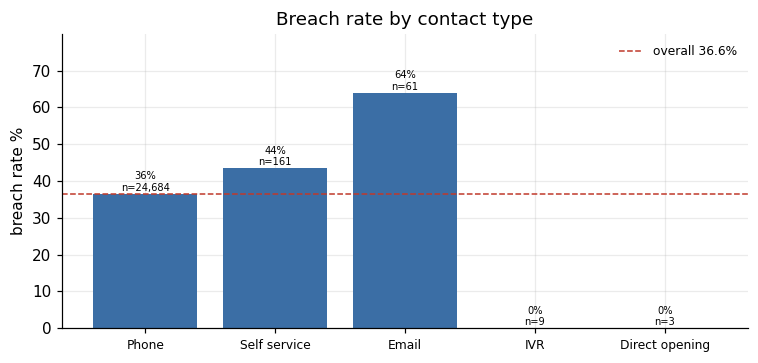

,incidents,breaches,share_of_incidents_%,breach_rate_%
contact_type_open,,,,
Phone,24684,9006,99.1,36.5
Self service,161,70,0.6,43.5
Email,61,39,0.2,63.9
IVR,9,0,0.0,0.0
Direct opening,3,0,0.0,0.0


In [17]:
segment("contact_type_open", "Breach rate by contact type")

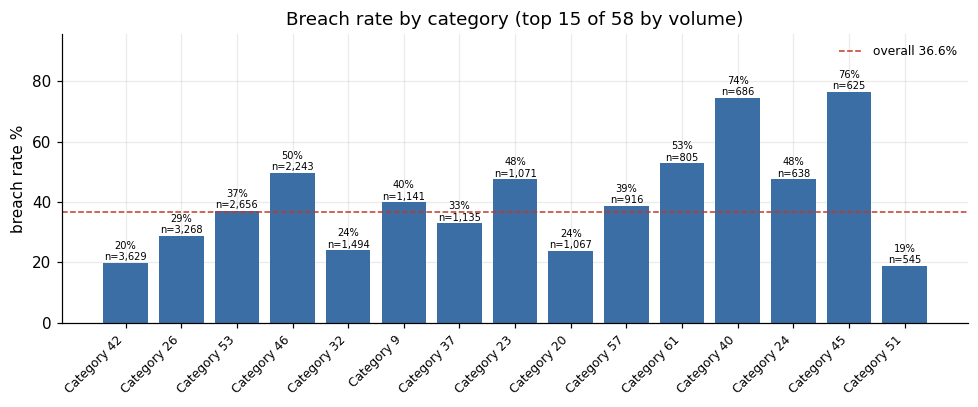

,incidents,breaches,share_of_incidents_%,breach_rate_%
category_open,,,,
Category 42,3629,722,14.6,19.9
Category 26,3268,945,13.1,28.9
Category 53,2656,985,10.7,37.1
Category 46,2243,1114,9.0,49.7
Category 32,1494,358,6.0,24.0
Category 9,1141,456,4.6,40.0
Category 37,1135,373,4.6,32.9
Category 23,1071,509,4.3,47.5
Category 20,1067,254,4.3,23.8


In [18]:
segment("category_open", "Breach rate by category", top=15, rotate=45, figsize=(9, 3.8))

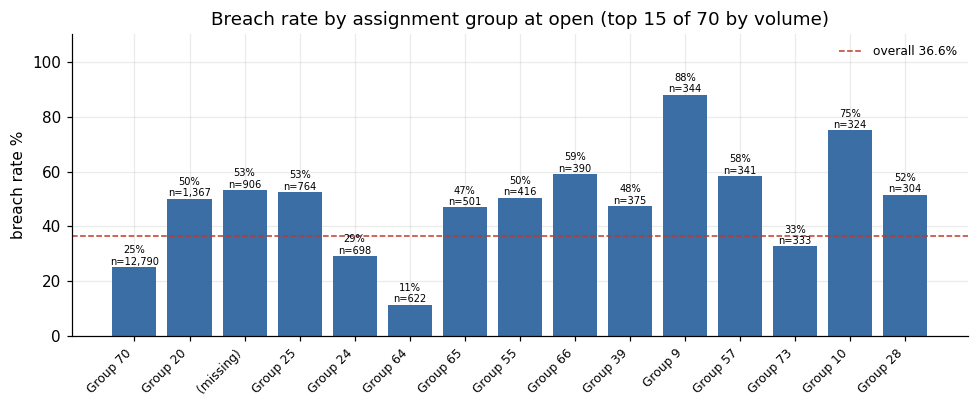

,incidents,breaches,share_of_incidents_%,breach_rate_%
assignment_group_open,,,,
Group 70,12790,3216,51.3,25.1
Group 20,1367,685,5.5,50.1
(missing),906,483,3.6,53.3
Group 25,764,402,3.1,52.6
Group 24,698,203,2.8,29.1
Group 64,622,71,2.5,11.4
Group 65,501,235,2.0,46.9
Group 55,416,210,1.7,50.5
Group 66,390,231,1.6,59.2


In [19]:
segment("assignment_group_open", "Breach rate by assignment group at open", top=15, rotate=45, figsize=(9, 3.8))

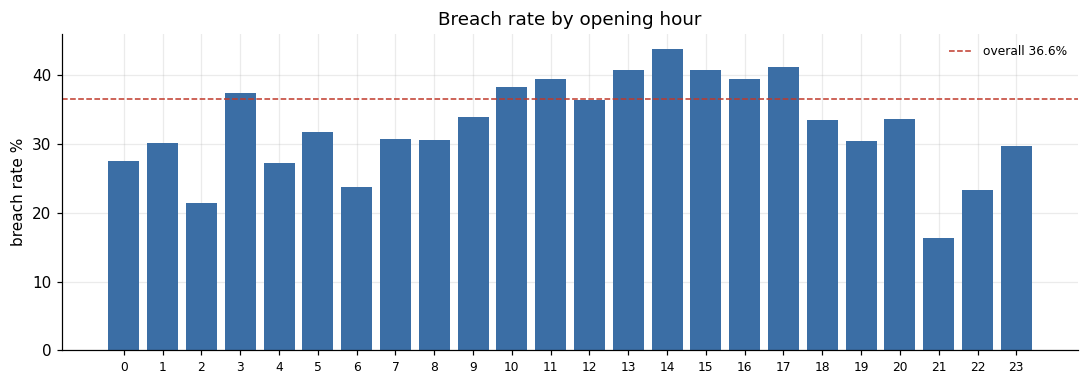

,incidents,breaches,share_of_incidents_%,breach_rate_%
open_hour,,,,
0,269,74,1.1,27.5
1,222,67,0.9,30.2
2,149,32,0.6,21.5
3,123,46,0.5,37.4
4,128,35,0.5,27.3
5,132,42,0.5,31.8
6,320,76,1.3,23.8
7,573,176,2.3,30.7
8,2547,779,10.2,30.6


In [20]:
segment("open_hour", "Breach rate by opening hour", order=list(range(24)), figsize=(10, 3.6))

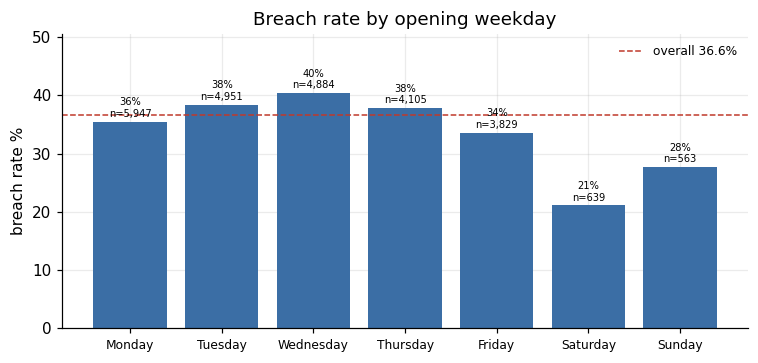

,incidents,breaches,share_of_incidents_%,breach_rate_%
open_weekday,,,,
Monday,5947,2113,23.9,35.5
Tuesday,4951,1900,19.9,38.4
Wednesday,4884,1974,19.6,40.4
Thursday,4105,1550,16.5,37.8
Friday,3829,1287,15.4,33.6
Saturday,639,135,2.6,21.1
Sunday,563,156,2.3,27.7


In [21]:
WEEKDAYS = ["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"]
segment("open_weekday", "Breach rate by opening weekday", order=WEEKDAYS)

In [22]:
# Remaining candidates, table only
for c in ["knowledge_open", "subcategory_open", "u_symptom_open"]:
    display(breach_table(c, top=8))

,incidents,breaches,share_of_incidents_%,breach_rate_%
knowledge_open,,,,
False,21363,6456,85.7,30.2
True,3555,2659,14.3,74.8


,incidents,breaches,share_of_incidents_%,breach_rate_%
subcategory_open,,,,
Subcategory 174,6644,2051,26.7,30.9
Subcategory 223,3736,754,15.0,20.2
Subcategory 175,1850,596,7.4,32.2
Subcategory 164,1242,519,5.0,41.8
Subcategory 9,876,206,3.5,23.5
Subcategory 135,573,200,2.3,34.9
Subcategory 275,563,182,2.3,32.3
Subcategory 170,493,208,2.0,42.2


,incidents,breaches,share_of_incidents_%,breach_rate_%
u_symptom_open,,,,
Symptom 491,9265,3073,37.2,33.2
(missing),5735,2524,23.0,44.0
Symptom 534,1669,76,6.7,4.6
Symptom 116,486,109,2.0,22.4
Symptom 387,375,125,1.5,33.3
Symptom 4,352,207,1.4,58.8
Symptom 506,351,15,1.4,4.3
Symptom 532,345,78,1.4,22.6


In [23]:
# How much does each open-time field separate breach rates? (groups with >= 100 incidents only)
rows = []
for c in [x + "_open" for x in CANDIDATES] + ["open_hour", "open_weekday"]:
    t = breach_table(c)
    big = t[t["incidents"] >= 100]
    rows.append({"feature": c, "groups": len(t), "groups_n>=100": len(big),
                 "min_breach_%": big["breach_rate_%"].min(), "max_breach_%": big["breach_rate_%"].max(),
                 "spread_pts": round(big["breach_rate_%"].max() - big["breach_rate_%"].min(), 1)})
pd.DataFrame(rows).set_index("feature").sort_values("spread_pts", ascending=False)

,groups,groups_n>=100,min_breach_%,max_breach_%,spread_pts
feature,,,,,
subcategory_open,247,32,5.9,96.2,90.3
priority_open,4,4,14.7,97.1,82.4
assignment_group_open,70,33,11.4,88.1,76.7
urgency_open,3,3,14.7,89.6,74.9
impact_open,3,3,14.0,86.0,72.0
category_open,58,22,8.2,76.5,68.3
u_symptom_open,501,24,3.2,59.2,56.0
knowledge_open,2,2,30.2,74.8,44.6
open_hour,24,24,16.4,43.8,27.4


**Reading section 4**
- **Overall breach rate: 36.6%** (9,115 of 24,918). SLA compliance in this log is 63.4%.
- **Priority / impact / urgency:** strong but concentrated. 95% of tickets are Moderate / Medium (36% breach). The small High and Critical groups breach **80–97%** of the time; Low breaches about 14%. The three fields move together.
- **Category, subcategory, symptom:** wide spread between groups (category 8% to 77% among groups with ≥100 tickets). Subcategory and symptom have hundreds of levels, most of them tiny, so rare levels need to be grouped before modelling. A missing symptom at open (23% of tickets) breaches more often (44%).
- **Assignment group at open:** `Group 70` receives 51% of all tickets at open (25% breach) — it looks like the front-line desk. Tickets that start in other groups mostly breach 45–90% of the time.
- **Opening hour:** business hours (10:00–17:00) breach 36–44%; nights and early mornings 16–37%. **Weekday:** Mon–Fri 34–40%, weekends 21–28% on low volume. The time zone of the timestamps is not documented.
- **Contact type:** 99.1% Phone. Effectively no signal.
- **Knowledge flag:** 75% vs 30% looks like the strongest binary split — but section 6 shows it is a calendar artefact, not a ticket property.

These are one-variable-at-a-time rates on the whole period. Section 7 shows the breach rate fell sharply after March 2016, so part of every difference above can be a time effect.

## 5. Hypothesis: more reassignments → more breaches? (BRD §9.2)

`reassignment_count` is taken from the **last** event (the total for the ticket). It is an outcome-time number, used here only to test the hypothesis — it is **not** a model feature.

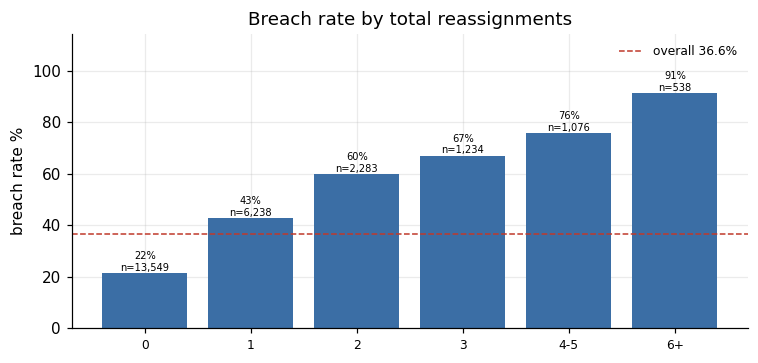

Spearman correlation, reassignment_count vs breached: 0.383


,incidents,breaches,share_of_incidents_%,breach_rate_%,median_hours_to_resolve
reassign_bucket,,,,,
0,13549,2928,54.4,21.6,0.7
1,6238,2678,25.0,42.9,42.0
2,2283,1373,9.2,60.1,103.0
3,1234,828,5.0,67.1,146.1
4-5,1076,816,4.3,75.8,192.1
6+,538,492,2.2,91.4,336.6


In [24]:
bins = [-1, 0, 1, 2, 3, 5, 100]
labels = ["0", "1", "2", "3", "4-5", "6+"]
inc["reassign_bucket"] = pd.cut(inc["reassignment_count_final"], bins=bins, labels=labels)
t5 = breach_table("reassign_bucket", order=labels)
t5["median_hours_to_resolve"] = inc.groupby("reassign_bucket", observed=True)["hours_to_resolve"].median().round(1)
breach_plot(t5, "Breach rate by total reassignments")
print("Spearman correlation, reassignment_count vs breached:",
      round(inc["reassignment_count_final"].corr(inc["breached"].astype(int), method="spearman"), 3))
t5

reassign_3,0 · breach %,1-2 · breach %,3+ · breach %,0 · n,1-2 · n,3+ · n
priority_open,,,,,,
1 - Critical,79.7,87.0,58.3,69,92,24
2 - High,97.7,97.0,96.1,128,132,51
3 - Moderate,20.9,47.0,75.7,12879,8095,2707
4 - Low,10.6,17.3,36.4,473,202,66


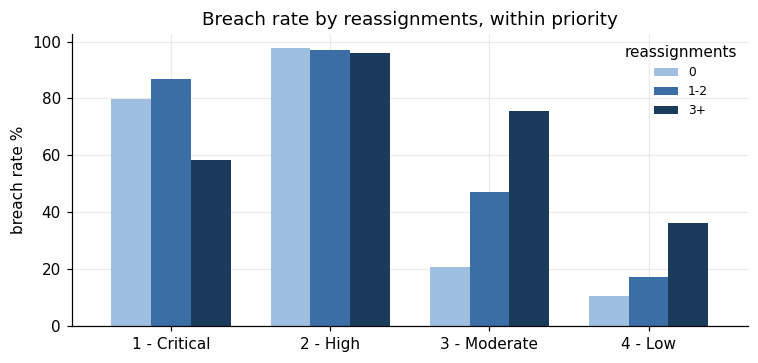

In [25]:
# Does the pattern hold inside each priority? (guards against priority mix driving the result)
inc["reassign_3"] = pd.cut(inc["reassignment_count_final"], bins=[-1, 0, 2, 100], labels=["0", "1-2", "3+"])
by_pri = inc.pivot_table(index="priority_open", columns="reassign_3", values="breached", aggfunc="mean", observed=True).mul(100).round(1)
n_pri = inc.pivot_table(index="priority_open", columns="reassign_3", values="breached", aggfunc="size", observed=True)
display(by_pri.add_suffix(" · breach %").join(n_pri.add_suffix(" · n")))

ax = by_pri.plot.bar(figsize=(7, 3.4), color=["#9fbfe0", "#3b6ea5", "#1b3a5c"], width=0.75)
ax.set_ylabel("breach rate %"); ax.set_xlabel(""); ax.set_title("Breach rate by reassignments, within priority")
ax.legend(title="reassignments", frameon=False, fontsize=8)
plt.xticks(rotation=0); plt.tight_layout(); plt.show()

In [26]:
# Does it hold in both time periods? (breach rates were much higher in Feb-Mar 2016, see section 7)
inc["period"] = np.where(inc["opened_at"] < "2016-04-01", "1) 29 Feb-Mar 2016",
                 np.where(inc["opened_at"] < "2016-06-01", "2) Apr-May 2016", "3) Jun 2016-Feb 2017"))
by_per = inc.pivot_table(index="period", columns="reassign_3", values="breached", aggfunc="mean", observed=True).mul(100).round(1)
n_per = inc.pivot_table(index="period", columns="reassign_3", values="breached", aggfunc="size", observed=True)
by_per.add_suffix(" · breach %").join(n_per.add_suffix(" · n"))

reassign_3,0 · breach %,1-2 · breach %,3+ · breach %,0 · n,1-2 · n,3+ · n
period,,,,,,
1) 29 Feb-Mar 2016,43.3,66.6,88.1,4094,3660,1448
2) Apr-May 2016,12.0,33.1,61.8,9311,4757,1374
3) Jun 2016-Feb 2017,29.9,38.5,46.2,144,104,26


**Answer: yes, as an association.** Breach rate climbs steadily with reassignments: **21.6%** with none → 42.9% with one → 60.1% with two → **91.4%** with six or more (Spearman 0.38).

- It holds inside Moderate and Low priority (98% of tickets) and inside each time period, so it is not just priority mix or the March effect.
- It does **not** show for Critical/High tickets: those breach 80–97% of the time whatever happens (and the groups are small).
- **Caveat — this is not proof of cause.** A ticket that stays open longer has more time to be reassigned, so slow tickets collect reassignments even if the reassignments did not cause the delay. The log cannot separate the two directions.
- 54% of tickets are never reassigned; 46% are reassigned at least once.

For the BRD hypothesis (§9.2): the data is consistent with "fewer reassignments → fewer breaches", but supports it as a correlation only.

## 6. Leakage check (FR-16)

For each candidate feature, compare the value at the first event with the value at the last event, and also count incidents where the value changed at *any* point (catches change-and-revert). A feature is safe only if we use the **first-event** value. Opening hour and weekday come from `opened_at`, which never changes inside an incident.

In [27]:
def norm(s):  # make missing comparable
    return s.astype(object).where(s.notna(), "(missing)")

rows = []
for c in CANDIDATES:
    f, l = norm(first[c]), norm(last[c])
    changed = f != l
    filled_later = (f == "(missing)") & (l != "(missing)")
    any_change = norm(df[c]).groupby(df["number"], sort=False).nunique() > 1
    rows.append({
        "feature": c,
        "missing_at_open_%": round((f == "(missing)").mean() * 100, 1),
        "changed_first_vs_last": int(changed.sum()),
        "changed_first_vs_last_%": round(changed.mean() * 100, 1),
        "of_which_missing_then_filled": int(filled_later.sum()),
        "changed_at_any_point_%": round(any_change.mean() * 100, 1),
    })
for c, s in [("open_hour", df["opened_at"].dt.hour), ("open_weekday", df["opened_at"].dt.dayofweek)]:
    ch = s.groupby(df["number"], sort=False).nunique() > 1
    rows.append({"feature": c, "missing_at_open_%": 0.0, "changed_first_vs_last": int(ch.sum()),
                 "changed_first_vs_last_%": round(ch.mean() * 100, 1), "of_which_missing_then_filled": 0,
                 "changed_at_any_point_%": round(ch.mean() * 100, 1)})
leak = pd.DataFrame(rows).set_index("feature")
leak

,missing_at_open_%,changed_first_vs_last,changed_first_vs_last_%,of_which_missing_then_filled,changed_at_any_point_%
feature,,,,,
contact_type,0.0,5,0.0,0,0.0
category,0.2,1184,4.8,32,4.9
subcategory,0.3,1763,7.1,61,7.2
u_symptom,23.0,1770,7.1,199,7.4
impact,0.0,292,1.2,0,1.3
urgency,0.0,284,1.1,0,1.2
priority,0.0,368,1.5,0,1.5
assignment_group,3.6,10142,40.7,503,45.5
knowledge,0.0,208,0.8,0,0.8


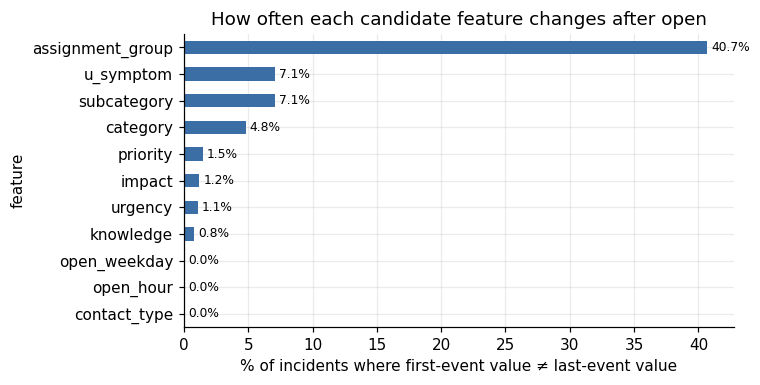

In [28]:
ax = leak["changed_first_vs_last_%"].sort_values().plot.barh(figsize=(7, 3.6), color=BAR)
ax.set_xlabel("% of incidents where first-event value ≠ last-event value")
ax.set_title("How often each candidate feature changes after open")
for i, v in enumerate(leak["changed_first_vs_last_%"].sort_values()):
    ax.text(v + 0.3, i, f"{v:.1f}%", va="center", fontsize=8)
plt.tight_layout(); plt.show()

In [29]:
# Does using the final value instead of the open value flatter the feature? (size of the leak if we got it wrong)
rows = []
for c in ["assignment_group", "priority", "knowledge", "u_symptom", "category", "subcategory", "impact", "urgency"]:
    ch = norm(first[c]) != norm(last[c])
    rows.append({"feature": c, "incidents_changed": int(ch.sum()),
                 "breach_%_if_changed": round(inc.loc[ch.values, "breached"].mean() * 100, 1),
                 "breach_%_if_unchanged": round(inc.loc[~ch.values, "breached"].mean() * 100, 1)})
display(pd.DataFrame(rows).set_index("feature"))

# Direction of priority changes and of the knowledge flag
print("Priority first -> last (changed only):")
display(pd.crosstab(first["priority"], last["priority"]))
print("knowledge flag first -> last:")
display(pd.crosstab(first["knowledge"], last["knowledge"]))

,incidents_changed,breach_%_if_changed,breach_%_if_unchanged
feature,,,
assignment_group,10142,52.8,25.4
priority,368,86.1,35.8
knowledge,208,74.0,36.3
u_symptom,1770,65.8,34.3
category,1184,72.9,34.8
subcategory,1763,69.9,34.0
impact,292,82.9,36.0
urgency,284,83.5,36.0


Priority first -> last (changed only):


priority,1 - Critical,2 - High,3 - Moderate,4 - Low
priority,,,,
1 - Critical,127,5,35,18
2 - High,16,280,11,4
3 - Moderate,123,123,23413,22
4 - Low,4,0,7,730


knowledge flag first -> last:


knowledge,False,True
knowledge,,
False,21261,102
True,106,3449


In [30]:
# Columns that are NOT open-time even though they sit on the first row (back-filled or running counters)
never = pd.DataFrame({
    "populated_on_first_event_%": [(first[c].notna().mean() * 100).round(1) for c in
        ["resolved_at", "closed_at", "closed_code", "resolved_by", "assigned_to", "made_sla"]],
    "first_event_state_New_only_%": [(first.loc[first["incident_state"] == "New", c].notna().mean() * 100).round(1) for c in
        ["resolved_at", "closed_at", "closed_code", "resolved_by", "assigned_to", "made_sla"]],
}, index=["resolved_at", "closed_at", "closed_code", "resolved_by", "assigned_to", "made_sla"])
never

,populated_on_first_event_%,first_event_state_New_only_%
resolved_at,93.8,99.9
closed_at,100.0,100.0
closed_code,99.6,99.4
resolved_by,99.6,99.9
assigned_to,71.3,58.7
made_sla,100.0,100.0


In [31]:
# Was the first event really the moment of opening? Gap between opened_at and the first logged update.
gap_min = (first["sys_updated_at"] - first["opened_at"]).dt.total_seconds() / 60
print(gap_min.describe(percentiles=[.5, .9, .99]).round(1).to_string())
print("First event more than 1 hour after opened_at: %.1f%%" % ((gap_min > 60).mean() * 100))
print("First event already Resolved: %.1f%% | breach rate of those: %.1f%%" % (
    (first["incident_state"] == "Resolved").mean() * 100,
    inc.loc[(first["incident_state"] == "Resolved").values, "breached"].mean() * 100))

count    24918.0
mean         5.2
std         14.7
min       -147.0
50%          1.0
90%         13.0
99%         49.8
max       1146.0
First event more than 1 hour after opened_at: 0.6%
First event already Resolved: 7.3% | breach rate of those: 16.3%


knowledge = true at open: 3555 incidents; 3550 of them opened on or before 10 Mar 2016; incidents opened by 10 Mar with knowledge = false: 1


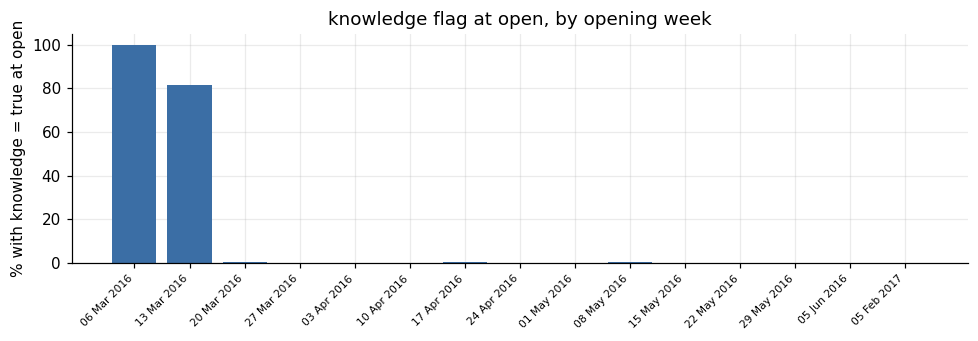

,incidents,knowledge_true_at_open,knowledge_true_%,breach_rate_%
opened_at,,,,
week ending 06 Mar 2016,1858,1857,99.9,55.9
week ending 13 Mar 2016,2073,1693,81.7,95.8
week ending 20 Mar 2016,1975,2,0.1,65.6
week ending 27 Mar 2016,1686,0,0.0,39.2
week ending 03 Apr 2016,2174,0,0.0,28.3
week ending 10 Apr 2016,2008,0,0.0,24.4
week ending 17 Apr 2016,1995,1,0.1,20.8
week ending 24 Apr 2016,1401,0,0.0,34.3
week ending 01 May 2016,2046,0,0.0,17.7


In [32]:
# The knowledge flag at open looked very predictive in section 4 (75% vs 30% breach). Check it against the calendar.
kw = inc.set_index("opened_at").resample("W").agg(incidents=("breached", "size"),
        knowledge_true_at_open=("knowledge_open", "sum"), breach_rate=("breached", "mean"))
kw = kw[kw["incidents"] >= 30]
kw["knowledge_true_%"] = (kw["knowledge_true_at_open"] / kw["incidents"] * 100).round(1)
kw["breach_rate_%"] = (kw.pop("breach_rate") * 100).round(1)
kw.index = kw.index.strftime("week ending %d %b %Y")
k = inc[inc["knowledge_open"]]
print("knowledge = true at open: %d incidents; %d of them opened on or before 10 Mar 2016; incidents opened by 10 Mar with knowledge = false: %d" % (
    len(k), (k["opened_at"] < "2016-03-11").sum(), ((inc["opened_at"] < "2016-03-11") & ~inc["knowledge_open"]).sum()))

fig, ax = plt.subplots(figsize=(9, 3.2))
ax.bar(range(len(kw)), kw["knowledge_true_%"], color=BAR)
ax.set_xticks(range(len(kw))); ax.set_xticklabels([i.replace("week ending ", "") for i in kw.index], rotation=45, ha="right", fontsize=7)
ax.set_ylabel("% with knowledge = true at open"); ax.set_title("knowledge flag at open, by opening week")
plt.tight_layout(); plt.show()
kw

**Leakage verdict per candidate feature** (use the **first-event** value in every case; never the final value)

| Feature | Known at open? | Changes first → last | Verdict |
|---|---|---|---|
| `contact_type` | Yes | 5 incidents (0.0%) | Safe. Almost no signal (99% Phone). |
| `impact` | Yes | 292 (1.2%) | Safe with first-event value. |
| `urgency` | Yes | 284 (1.1%) | Safe with first-event value. |
| `priority` | Yes | 368 (1.5%) | Safe with first-event value. Changes are mostly upgrades from Moderate. |
| `category` | Yes (0.2% missing at open) | 1,184 (4.8%) | Safe with first-event value. |
| `subcategory` | Yes (0.3% missing) | 1,763 (7.1%) | Safe with first-event value. Group rare levels. |
| `u_symptom` | Partly — 23% missing at open | 1,770 (7.1%); 199 filled in later | Safe with first-event value; keep "missing" as its own level. |
| `assignment_group` | Yes (3.6% missing at open) | **10,142 (40.7%)** | Safe **only** as the first-event value. The final group is leakage. |
| `knowledge` | Value present, but see below | 208 (0.8%) | **Drop.** Calendar artefact. |
| opening hour / weekday | Yes — derived from `opened_at`, which never changes | 0 | Safe. |

**Why the first-event rule matters.** Tickets whose fields were edited later breach far more often (53–86%) than tickets whose fields never changed (25–36%), simply because long-running tickets get edited more. Training on final values would let the model see that.

**Why `knowledge` is dropped.** It is `true` at open for 3,550 of the 3,551 incidents opened from 29 Feb to 10 Mar 2016, and for only 5 incidents after that. It does not describe the ticket; it marks "opened in the first 11 days of the log", which was the worst period for breaches. A model would learn the date, and the flag would be constant in any later test set.

**Columns that sit on the first row but are not open-time** (never features): `resolved_at`, `closed_at`, `closed_code`, `resolved_by` are back-filled onto every event; `made_sla`, `reassignment_count`, `reopen_count`, `sys_mod_count`, `incident_state`, `active`, `assigned_to`, `sys_updated_*` change as the ticket moves.

**Limits of this check (unverified):**
- "First event" is the first *logged* event. It is logged a median of 1 minute after `opened_at` (99% within 50 minutes), so it is a close stand-in for open time, but not exact.
- 7.3% of incidents are already `Resolved` on their first event (resolved on first contact; 16% breach). Their open-time values are still valid, but a risk score for them has little use.
- A field that never changes could in principle have been back-filled like `resolved_at`. The data cannot rule that out for `category`, `impact`, etc.; the fact that they do change in 1–7% of incidents suggests they are recorded live.

## 7. Date range of `opened_at` (for the time-based split, NFR-12)

In [33]:
print("opened_at  :", inc["opened_at"].min(), "→", inc["opened_at"].max())
print("closed_at  :", inc["closed_at"].min(), "→", inc["closed_at"].max())
print("last event :", df["sys_updated_at"].min(), "→", df["sys_updated_at"].max())

monthly = inc.groupby(inc["opened_at"].dt.to_period("M")).agg(
    incidents=("breached", "size"), breach_rate=("breached", "mean"), median_hours_to_resolve=("hours_to_resolve", "median"))
monthly["share_%"] = (monthly["incidents"] / len(inc) * 100).round(1)
monthly["cum_share_%"] = monthly["share_%"].cumsum().round(1)
monthly["breach_rate_%"] = (monthly.pop("breach_rate") * 100).round(1)
monthly["median_hours_to_resolve"] = monthly["median_hours_to_resolve"].round(1)
monthly

opened_at  : 2016-02-29 01:16:00 → 2017-02-16 14:17:00
closed_at  : 2016-02-29 17:47:00 → 2017-02-18 15:00:00
last event : 2016-02-29 01:23:00 → 2017-02-18 15:00:00


,incidents,median_hours_to_resolve,share_%,cum_share_%,breach_rate_%
opened_at,,,,,
2016-02,207,53.8,0.8,0.8,35.3
2016-03,8995,71.2,36.1,36.9,60.1
2016-04,7934,4.3,31.8,68.7,23.3
2016-05,7508,2.9,30.1,98.8,22.5
2016-06,5,26.6,0.0,98.8,20.0
2016-07,14,34.8,0.1,98.9,21.4
2016-08,15,145.2,0.1,99.0,53.3
2016-09,12,64.4,0.0,99.0,41.7
2016-10,16,111.0,0.1,99.1,56.2


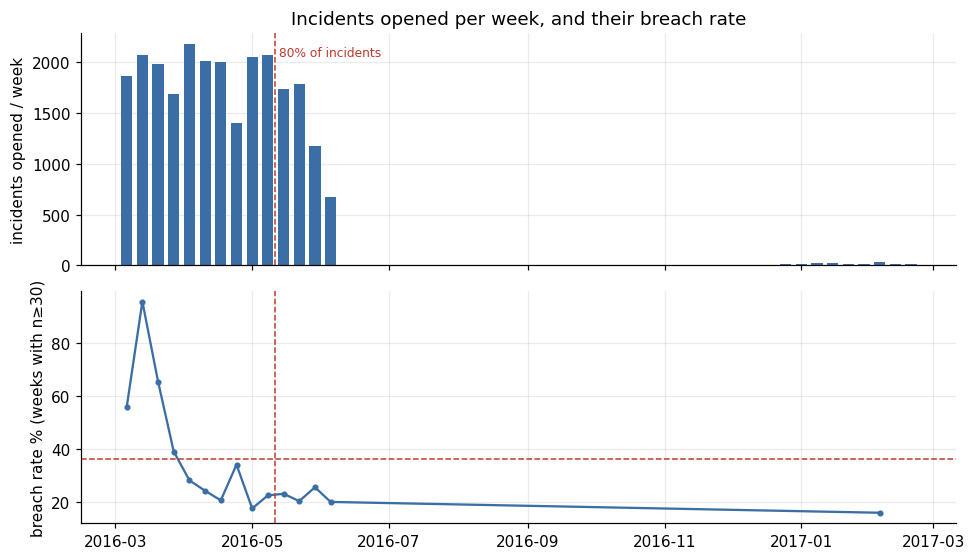

cut at 50% → 12 Apr 2016: train 12,460 (breach 49.9%) | test 12,458 (breach 23.3%)
cut at 70% → 02 May 2016: train 17,442 (breach 42.3%) | test 7,476 (breach 23.3%)
cut at 80% → 11 May 2016: train 19,934 (breach 40.0%) | test 4,984 (breach 23.0%)
cut at 90% → 20 May 2016: train 22,426 (breach 38.0%) | test 2,492 (breach 23.8%)


In [34]:
weekly = inc.set_index("opened_at").resample("W")["breached"].agg(["size", "mean"])
weekly = weekly[weekly["size"] > 0]
cut80 = inc["opened_at"].quantile(0.80)

fig, (a1, a2) = plt.subplots(2, 1, figsize=(9, 5.2), sharex=True)
a1.bar(weekly.index, weekly["size"], width=5, color=BAR); a1.set_ylabel("incidents opened / week")
a1.axvline(cut80, color=REF, ls="--", lw=1); a1.text(cut80, a1.get_ylim()[1] * 0.9, " 80% of incidents", color=REF, fontsize=8)
a1.set_title("Incidents opened per week, and their breach rate")
big = weekly[weekly["size"] >= 30]
a2.plot(big.index, big["mean"] * 100, marker="o", ms=3, color=BAR); a2.set_ylabel("breach rate % (weeks with n≥30)")
a2.axhline(overall * 100, color=REF, ls="--", lw=1); a2.axvline(cut80, color=REF, ls="--", lw=1)
plt.tight_layout(); plt.show()

for p in [0.5, 0.7, 0.8, 0.9]:
    d = inc["opened_at"].quantile(p)
    tr, te = inc[inc["opened_at"] <= d], inc[inc["opened_at"] > d]
    print(f"cut at {int(p*100)}% → {d:%d %b %Y}: train {len(tr):,} (breach {tr['breached'].mean():.1%}) | test {len(te):,} (breach {te['breached'].mean():.1%})")

**Reading section 7**
- `opened_at` runs from **29 Feb 2016 to 16 Feb 2017**, but **98.9% of incidents were opened between 29 Feb and 31 May 2016**. Only 274 incidents (1.1%) were opened in the eight and a half months after that — a thin tail, not a continuous feed.
- **The breach rate is not stable over time.** March 2016: **60%**. April and May: **23%**. Median time to resolve fell from 71 hours (March) to about 3–4 hours (April–May). The log does not say why.
- A time-based split therefore trains on a harder period than it tests on. With a cut at the 80th percentile (11 May 2016): train 19,934 incidents at 40.0% breach, test 4,984 at 23.0%.

**Suggested split (owner to confirm):** cut at the 80th percentile of `opened_at`, which falls on 11 May 2016 — earlier incidents train, later incidents test. Expect predicted probabilities to run high on the test set; judge the model on ranking (PR-AUC, recall at the top of the list) and check calibration separately.

## Summary

| # | Question | Short answer |
|---|---|---|
| 1 | Shape | 141,712 events × 36 columns, 24,918 incidents, `?` = missing |
| 2 | One row per incident | Built: first event = open-time, last event = outcome |
| 3 | `made_sla` | `false` = breached (final value). Proved three ways |
| 4 | Breach rate | 36.6% overall; strongest splits are priority/impact/urgency, category/subcategory, assignment group at open |
| 5 | Reassignments | 21.6% breach with none → 91.4% with 6+. Association, not proven cause |
| 6 | Leakage | First-event values only. `assignment_group` changes in 40.7% of incidents. `knowledge` dropped |
| 7 | Dates | 29 Feb 2016 – 16 Feb 2017; 98.9% by end of May 2016; breach rate 60% in March vs 23% after |

**Final open-time feature list (FR-16), all taken from the first event:**
`priority`, `impact`, `urgency`, `category`, `subcategory`, `u_symptom`, `assignment_group`, `open_hour`, `open_weekday`, and optionally `contact_type` (safe, near-zero signal).

**Removed from the SRS candidate list:** `knowledge` (calendar artefact).

Written summary: `docs/eda-findings.md`. No model was trained.